In [21]:
import numpy as np
import pandas as pd
from pathlib import Path
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
import torch.nn as nn

# Make modules in src/ available
import sys
project_root = Path("..").resolve()
src_path = project_root / "src"

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from mlp_advanced import train_mlp_advanced



In [3]:
monk_urls = {
    "monk1": "https://archive.ics.uci.edu/ml/machine-learning-databases/monks-problems/monks-1.train",
    "monk2": "https://archive.ics.uci.edu/ml/machine-learning-databases/monks-problems/monks-2.train",
    "monk3": "https://archive.ics.uci.edu/ml/machine-learning-databases/monks-problems/monks-3.train",
}

def load_monk(url):
    df = pd.read_csv(url, delim_whitespace=True, header=None, comment=';')
    df = df.dropna()  # remove malformed or empty rows
    df.columns = ["label", "a1", "a2", "a3", "a4", "a5", "a6", "id"]
    df = df.drop(columns=["id"])
    df["label"] = df["label"].astype(int)
    return df


monk1 = load_monk(monk_urls["monk1"])
monk2 = load_monk(monk_urls["monk2"])
monk3 = load_monk(monk_urls["monk3"])

print("MONK-1:", monk1.shape)
print("MONK-2:", monk2.shape)
print("MONK-3:", monk3.shape)


C:\Users\nourh\AppData\Local\Temp\ipykernel_24072\2314329750.py:8: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True, header=None, comment=';')
C:\Users\nourh\AppData\Local\Temp\ipykernel_24072\2314329750.py:8: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True, header=None, comment=';')
C:\Users\nourh\AppData\Local\Temp\ipykernel_24072\2314329750.py:8: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(url, delim_whitespace=True, header=None, comment=';')


MONK-1: (124, 7)
MONK-2: (169, 7)
MONK-3: (122, 7)


In [4]:
def preprocess_monk(df):
    X = df.drop(columns=["label"])
    y = df["label"].astype(int).values

    enc = OneHotEncoder(sparse_output=False)
    X_encoded = enc.fit_transform(X)

    return X_encoded.astype(np.float32), y, enc

X1, y1, enc1 = preprocess_monk(monk1)
X2, y2, enc2 = preprocess_monk(monk2)
X3, y3, enc3 = preprocess_monk(monk3)

X1.shape, X2.shape, X3.shape


((124, 17), (169, 17), (122, 17))

In [5]:
def split(X, y):
    return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X1_tr, X1_val, y1_tr, y1_val = split(X1, y1)
X2_tr, X2_val, y2_tr, y2_val = split(X2, y2)
X3_tr, X3_val, y3_tr, y3_val = split(X3, y3)


In [6]:
def one_hot(y):
    K = len(np.unique(y))
    Y = np.zeros((len(y), K))
    Y[np.arange(len(y)), y] = 1
    return Y.astype(np.float32)

y1_tr_oh = one_hot(y1_tr)
y1_val_oh = one_hot(y1_val)

y2_tr_oh = one_hot(y2_tr)
y2_val_oh = one_hot(y2_val)

y3_tr_oh = one_hot(y3_tr)
y3_val_oh = one_hot(y3_val)


In [7]:
mlp_params = {
    "hidden_layers": [32, 16],
    "activation": "relu",
    "lr": 0.01,
    "weight_decay": 0.0001,
    "dropout": 0.0,
    "batch_size": 16,
    "patience": 200,
    "seed": 0,
}


In [8]:
model1, hist1, val_mee1 = train_mlp_advanced(
    X1_tr, y1_tr_oh,
    X1_val, y1_val_oh,
    **mlp_params,
    verbose=True
)

# Predict
X1_val_t = torch.tensor(X1_val, dtype=torch.float32)
with torch.no_grad():
    y_pred1 = model1(X1_val_t).numpy()

acc1 = accuracy_score(y1_val, np.argmax(y_pred1, axis=1))
acc1


Epoch 0 | Train MEE=0.7238, Val MEE=0.6482, LR=1.00e-02
Epoch 100 | Train MEE=0.0121, Val MEE=0.2150, LR=1.00e-02
Epoch 200 | Train MEE=0.0152, Val MEE=0.1667, LR=1.00e-02
Epoch 300 | Train MEE=0.0068, Val MEE=0.1207, LR=1.00e-02
Epoch 400 | Train MEE=0.0246, Val MEE=0.0884, LR=1.00e-02
Epoch 500 | Train MEE=0.0287, Val MEE=0.0664, LR=1.00e-02
Epoch 600 | Train MEE=0.0090, Val MEE=0.0375, LR=5.00e-03
Epoch 700 | Train MEE=0.0039, Val MEE=0.0379, LR=2.50e-03
Epoch 800 | Train MEE=0.0024, Val MEE=0.0382, LR=6.25e-04
Early stopping at epoch 806


1.0

In [9]:
model2, hist2, val_mee2 = train_mlp_advanced(
    X2_tr, y2_tr_oh,
    X2_val, y2_val_oh,
    **mlp_params,
    verbose=False
)

X2_val_t = torch.tensor(X2_val, dtype=torch.float32)
with torch.no_grad():
    y_pred2 = model2(X2_val_t).numpy()

acc2 = accuracy_score(y2_val, np.argmax(y_pred2, axis=1))
acc2


1.0

In [10]:
model3, hist3, val_mee3 = train_mlp_advanced(
    X3_tr, y3_tr_oh,
    X3_val, y3_val_oh,
    **mlp_params,
    verbose=False
)

X3_val_t = torch.tensor(X3_val, dtype=torch.float32)
with torch.no_grad():
    y_pred3 = model3(X3_val_t).numpy()

acc3 = accuracy_score(y3_val, np.argmax(y_pred3, axis=1))
acc3


0.96

In [11]:
def svm_acc(X_tr, y_tr, X_val, y_val):
    svm = SVC(kernel="rbf", gamma="scale", C=1.0)
    svm.fit(X_tr, y_tr)
    y_pred = svm.predict(X_val)
    return accuracy_score(y_val, y_pred)

svm1 = svm_acc(X1_tr, y1_tr, X1_val, y1_val)
svm2 = svm_acc(X2_tr, y2_tr, X2_val, y2_val)
svm3 = svm_acc(X3_tr, y3_tr, X3_val, y3_val)

svm1, svm2, svm3


(0.88, 0.6764705882352942, 0.96)

In [12]:
from sklearn.metrics import accuracy_score, mean_squared_error
import numpy as np

def monk_metrics(model, X_tr, y_tr_oh, y_tr,
                        X_te, y_te_oh, y_te):
    
    # Predict
    with torch.no_grad():
        y_pred_tr = model(torch.tensor(X_tr, dtype=torch.float32)).numpy()
        y_pred_te = model(torch.tensor(X_te, dtype=torch.float32)).numpy()

    # Classification accuracy
    acc_tr = accuracy_score(y_tr, np.argmax(y_pred_tr, axis=1))
    acc_te = accuracy_score(y_te, np.argmax(y_pred_te, axis=1))

    # MSE (note: professor wants MSE, not CE)
    mse_tr = mean_squared_error(y_tr_oh, y_pred_tr)
    mse_te = mean_squared_error(y_te_oh, y_pred_te)

    return mse_tr, mse_te, acc_tr, acc_te


In [13]:
import pandas as pd

table_rows = []

for task_name, (model, Xtr, ytr_oh, ytr, Xte, yte_oh, yte, params) in {
    "MONK1": (model1, X1_tr, y1_tr_oh, y1_tr, X1_val, y1_val_oh, y1_val, mlp_params),
    "MONK2": (model2, X2_tr, y2_tr_oh, y2_tr, X2_val, y2_val_oh, y2_val, mlp_params),
    "MONK3": (model3, X3_tr, y3_tr_oh, y3_tr, X3_val, y3_val_oh, y3_val, mlp_params)
}.items():
    
    mse_tr, mse_te, acc_tr, acc_te = monk_metrics(
        model, Xtr, ytr_oh, ytr, Xte, yte_oh, yte
    )

    table_rows.append({
        "Task": task_name,
        "Hyperparameters": params,
        "MSE (TR/TS)": f"{mse_tr:.4f} / {mse_te:.4f}",
        "Accuracy (TR/TS)": f"{acc_tr:.3f} / {acc_te:.3f}",
    })

monk_table = pd.DataFrame(table_rows)
monk_table


,Task,Hyperparameters,MSE (TR/TS),Accuracy (TR/TS)
0,MONK1,"{'hidden_layers': [32, 16], 'activation': 'rel...",0.0000 / 0.0023,1.000 / 1.000
1,MONK2,"{'hidden_layers': [32, 16], 'activation': 'rel...",0.0000 / 0.0000,1.000 / 1.000
2,MONK3,"{'hidden_layers': [32, 16], 'activation': 'rel...",0.0001 / 0.0736,1.000 / 0.960


In [19]:
from mlp_advanced import AdvancedMLP,train_mlp_advanced

def train_mlp_monk(X_train, y_train_oh, X_val, y_val_oh,
                   hidden_layers=[16, 8],
                   lr=0.01, weight_decay=0.0,
                   epochs=500, batch_size=16, seed=0):

    torch.manual_seed(seed)
    np.random.seed(seed)

    input_dim = X_train.shape[1]
    output_dim = y_train_oh.shape[1]

    model = AdvancedMLP(
        input_dim=input_dim,
        hidden_layers=hidden_layers,
        output_dim=output_dim,
        activation="relu",
        dropout=0.0
    )

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    Xtr = torch.tensor(X_train, dtype=torch.float32)
    ytr = torch.tensor(y_train_oh, dtype=torch.float32)
    Xv = torch.tensor(X_val, dtype=torch.float32)
    yv = torch.tensor(y_val_oh, dtype=torch.float32)

    for ep in range(epochs):
        # ---- Training ----
        model.train()
        optimizer.zero_grad()
        pred = model(Xtr)
        loss = loss_fn(pred, ytr)
        loss.backward()
        optimizer.step()

        # ---- Validation ----
        model.eval()
        with torch.no_grad():
            pred_val = model(Xv)
            loss_val = loss_fn(pred_val, yv)

            acc_tr = accuracy_score(np.argmax(y_train_oh, axis=1),
                                    np.argmax(pred.numpy(), axis=1))
            acc_val = accuracy_score(np.argmax(y_val_oh, axis=1),
                                     np.argmax(pred_val.numpy(), axis=1))

        # Save history
        history["train_loss"].append(loss.item())
        history["val_loss"].append(loss_val.item())
        history["train_acc"].append(acc_tr)
        history["val_acc"].append(acc_val)

    return model, history


In [22]:
model1, hist1 = train_mlp_monk(
    X1_tr, y1_tr_oh,
    X1_val, y1_val_oh,
    hidden_layers=[16, 8],
    lr=0.01,
    weight_decay=0.0001,
    epochs=300
)


In [23]:
model2, hist2 = train_mlp_monk(
    X2_tr, y2_tr_oh,
    X2_val, y2_val_oh,
    hidden_layers=[16, 8],
    lr=0.01,
    weight_decay=0.0001,
    epochs=300
)


In [24]:
model3, hist3 = train_mlp_monk(
    X3_tr, y3_tr_oh,
    X3_val, y3_val_oh,
    hidden_layers=[16, 8],
    lr=0.005,      # slightly smaller for MONK-3
    weight_decay=0.0001,
    epochs=300
)


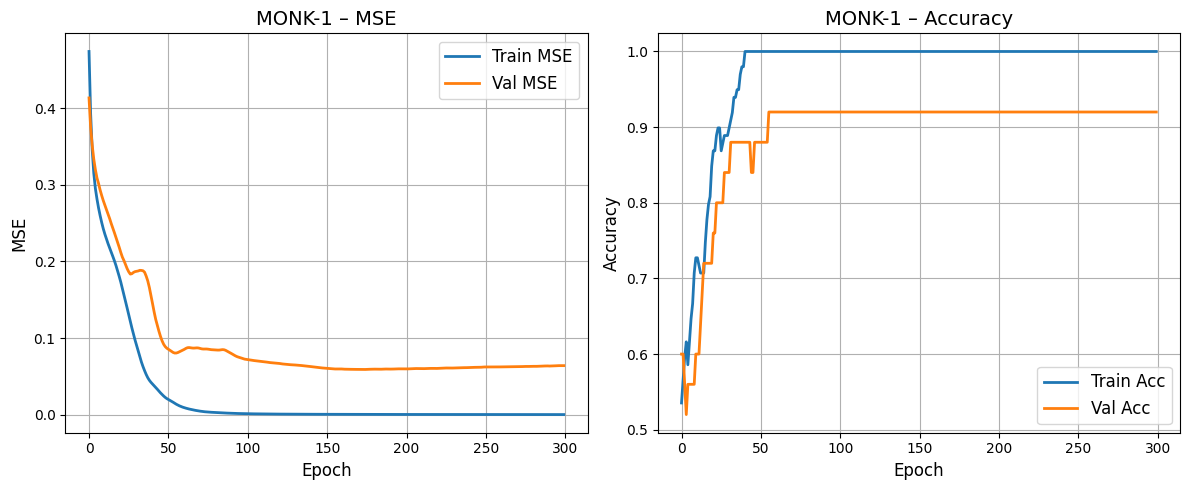

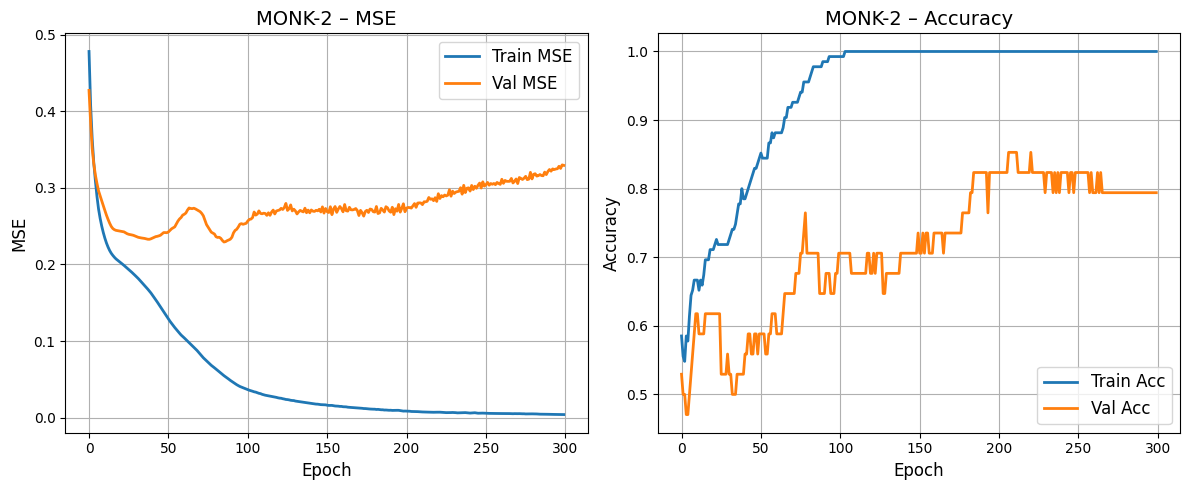

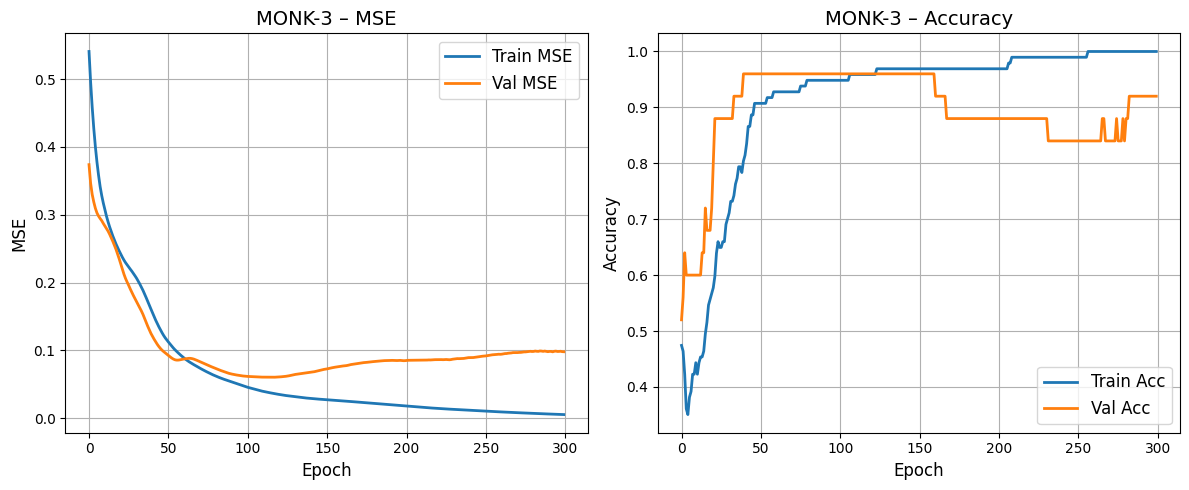

In [25]:
plot_learning_curves(hist1, "MONK-1")
plot_learning_curves(hist2, "MONK-2")
plot_learning_curves(hist3, "MONK-3")
